# Phase 1: PINEM sidebands

This notebook only calls the `fepc` package and the figure script. The theory is in `docs/theory.md`, and the checks are in `tests/test_pinem.py`.

In [1]:
import sys

from fepc.constants import joule_to_ev, photon_energy
from fepc.pinem import (
    G_AT_P0_ZERO,
    sideband_merge_fwhm,
    sideband_orders,
    sideband_probabilities,
)

sys.path.append("../scripts")
import make_figures

%matplotlib inline

## Sideband probabilities

An electron exchanges $n$ photons with probability $P_n=J_n^2(2|g|)$. First, two reference numbers: the photon energy, and the coupling strength at which the zero-loss peak first empties.

In [2]:
hbar_omega = photon_energy(1550e-9)
print(f"Photon energy at 1550 nm: {joule_to_ev(hbar_omega):.4f} eV")
print(f"P_0 first vanishes at |g| = {G_AT_P0_ZERO:.4f}")

Photon energy at 1550 nm: 0.7999 eV
P_0 first vanishes at |g| = 1.2024


The sum rules hold at each of these coupling strengths, from weak coupling to far beyond the perturbative range:

In [3]:
print("   |g|    sum P_n    sum n^2 P_n    2|g|^2")
for g in [0.1, 1.0, G_AT_P0_ZERO, 3.0, 10.0]:
    n = sideband_orders(g)
    p = sideband_probabilities(g, n)
    print(f"{g:7.4f}  {p.sum():.10f}  {(n**2 * p).sum():11.6f}  {2 * g**2:11.6f}")

   |g|    sum P_n    sum n^2 P_n    2|g|^2
 0.1000  1.0000000000     0.020000     0.020000
 1.0000  1.0000000000     2.000000     2.000000
 1.2024  1.0000000000     2.891593     2.891593
 3.0000  1.0000000000    18.000000    18.000000
10.0000  1.0000000000   200.000000   200.000000


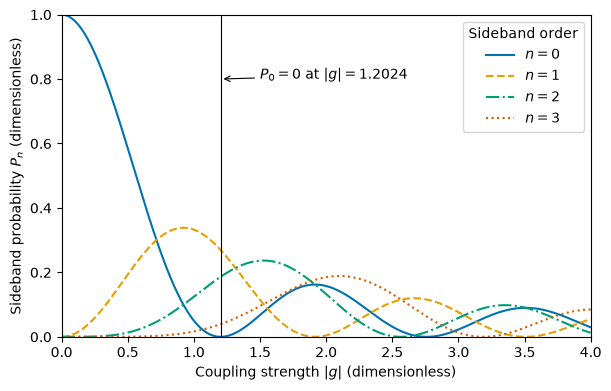

In [4]:
fig = make_figures.pinem_probabilities_figure()

## Spectra

A spectrometer sees each sideband broadened by the zero-loss peak. At 1550 nm the sidebands are only 0.80 eV apart, so the width of the peak matters. Two equal peaks this far apart would lose the dip between them at the FWHM printed below. That is a rule of thumb for one pair. In the middle panel the 1.0 eV curve, just above the printed value, has lost its separate sideband peaks but keeps a deep dip at $E=0$, because $P_0$ is empty there.

Two-peak merge at FWHM = 0.942 eV


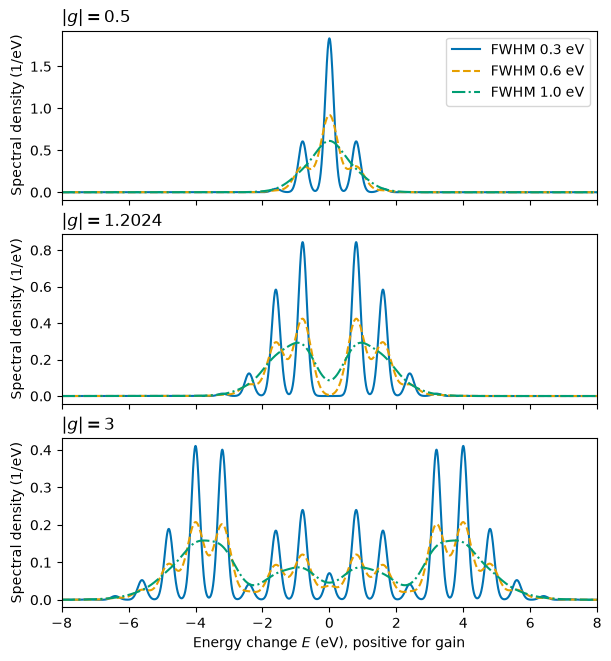

In [5]:
print(f"Two-peak merge at FWHM = {joule_to_ev(sideband_merge_fwhm(hbar_omega)):.3f} eV")
fig = make_figures.pinem_spectra_figure()

## Averaging over $|g|$

Electrons arriving at different times sample different values of $|g|$ on a pulse envelope, and their probabilities add. The left panel shows the zero of $P_0$ filling in as the arrival-time spread $\sigma_\tau$ grows relative to the envelope width $T$. The right panel shows the same averaging in the spectrum: weight moves from the outer lobes towards $E=0$.

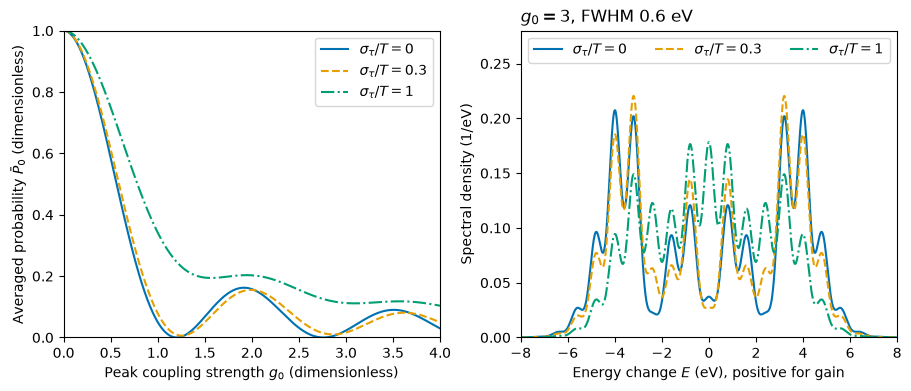

In [6]:
fig = make_figures.pinem_averaging_figure()